# Consommation d'antidiabétiques en France (Open Medic 2024)

**Question :** qui consomme des antidiabétiques en France, quels médicaments, et qui les prescrit ?

**Données :** Open Medic 2024 (Assurance maladie, extrait du SNDS), classe ATC A10 « Médicaments du diabète ». Source : [ameli.fr](https://www.assurance-maladie.ameli.fr/etudes-et-donnees/open-medic-base-complete-depenses-medicaments) · Licence Ouverte Etalab.

**Auteure :** Linda MISLANGE MEGOUKENG TEGIEU

## 1. Chargement du fichier

Le fichier Open Medic 2024 (zip téléchargé depuis ameli.fr) est importé dans Colab puis décompressé.

In [4]:
from google.colab import files
import zipfile, os, shutil

envoi = files.upload()
nom = list(envoi)[0]
os.makedirs("openmedic_2024", exist_ok=True)
if zipfile.is_zipfile(nom):
    zipfile.ZipFile(nom).extractall("openmedic_2024")
else:
    shutil.move(nom, os.path.join("openmedic_2024", nom))
print("Fichiers :", os.listdir("openmedic_2024"))

Saving OPEN_MEDIC_2024 (1).zip to OPEN_MEDIC_2024 (1).zip
Fichiers : ['OPEN_MEDIC_2024.CSV']


## 2. Exploration : structure du fichier

Détection automatique du séparateur et de l'encodage, puis affichage des colonnes.

In [5]:
import glob, os, pandas as pd

candidats = [f for f in glob.glob("openmedic_2024/**/*", recursive=True) if os.path.isfile(f)]
print("Fichiers trouvés :", candidats)
if not candidats:
    raise SystemExit("Aucun fichier trouvé.")
fichier = max(candidats, key=os.path.getsize)      # le plus gros fichier = les données
print("Fichier utilisé :", fichier)

def apercu(chemin, n=5):
    for sep in [";", ",", "\t"]:
        for enc in ["latin-1", "utf-8"]:
            try:
                d = pd.read_csv(chemin, sep=sep, encoding=enc, nrows=n)
                if d.shape[1] > 3:
                    return d, sep, enc
            except Exception:
                pass
    raise ValueError("Format non reconnu")

extrait, SEP, ENC = apercu(fichier)
print("\nNOMS DES COLONNES :")
for i, col in enumerate(extrait.columns, 1):
    print(f"  {i}. {col}")
extrait

Fichiers trouvés : ['openmedic_2024/OPEN_MEDIC_2024.CSV']
Fichier utilisé : openmedic_2024/OPEN_MEDIC_2024.CSV

NOMS DES COLONNES :
  1. ATC1
  2. l_ATC1
  3. ATC2
  4. L_ATC2
  5. ATC3
  6. L_ATC3
  7. ATC4
  8. L_ATC4
  9. ATC5
  10. L_ATC5
  11. CIP13
  12. l_cip13
  13. TOP_GEN
  14. GEN_NUM
  15. age
  16. sexe
  17. BEN_REG
  18. PSP_SPE
  19. BOITES
  20. REM
  21. BSE


,ATC1,l_ATC1,ATC2,L_ATC2,ATC3,L_ATC3,ATC4,L_ATC4,ATC5,L_ATC5,...,l_cip13,TOP_GEN,GEN_NUM,age,sexe,BEN_REG,PSP_SPE,BOITES,REM,BSE
0,A,SYSTEME DIGESTIF ET METABOLISME,A01,PREPARATIONS STOMATOLOGIQUES,A01A,PREPARATIONS STOMATOLOGIQUES,A01AA,MEDICAMENTS PROPHYLACTIQUES ANTICARIES,A01AA01,SODIUM FLUORURE,...,FLUOGEL GEL DENTAIRE 1,0,0,99,9,99,99,14,"38,54","51,38"
1,A,SYSTEME DIGESTIF ET METABOLISME,A01,PREPARATIONS STOMATOLOGIQUES,A01A,PREPARATIONS STOMATOLOGIQUES,A01AA,MEDICAMENTS PROPHYLACTIQUES ANTICARIES,A01AA01,SODIUM FLUORURE,...,"ZYMAFLUOR 0,50MG CPR 100",0,0,0,1,5,1,25,"13,06","41,45"
2,A,SYSTEME DIGESTIF ET METABOLISME,A01,PREPARATIONS STOMATOLOGIQUES,A01A,PREPARATIONS STOMATOLOGIQUES,A01AA,MEDICAMENTS PROPHYLACTIQUES ANTICARIES,A01AA01,SODIUM FLUORURE,...,"ZYMAFLUOR 0,50MG CPR 100",0,0,0,1,5,99,20,"10,18","33,92"
3,A,SYSTEME DIGESTIF ET METABOLISME,A01,PREPARATIONS STOMATOLOGIQUES,A01A,PREPARATIONS STOMATOLOGIQUES,A01AA,MEDICAMENTS PROPHYLACTIQUES ANTICARIES,A01AA01,SODIUM FLUORURE,...,"ZYMAFLUOR 0,50MG CPR 100",0,0,0,1,11,1,114,"48,89","147,48"
4,A,SYSTEME DIGESTIF ET METABOLISME,A01,PREPARATIONS STOMATOLOGIQUES,A01A,PREPARATIONS STOMATOLOGIQUES,A01AA,MEDICAMENTS PROPHYLACTIQUES ANTICARIES,A01AA01,SODIUM FLUORURE,...,"ZYMAFLUOR 0,50MG CPR 100",0,0,0,1,11,12,404,"157,83","521,16"


In [6]:
# Noms des colonnes utilisées
COL_ATC2 = "ATC2"      # le CODE de la classe ATC niveau 2 (celle qui contient "A10")
COL_ATC5 = "ATC5"      # le CODE de la molécule (niveau 5)
COL_LIB5 = "L_ATC5"      # le LIBELLÉ de la molécule (son nom en lettres)
COL_BOITES = "BOITES"    # le nombre de boîtes
COL_REM = "REM"       # le montant remboursé
COL_AGE = "age"
COL_SEXE = "sexe"
COL_REG = "BEN_REG"       # la région du bénéficiaire
COL_PRESC = "PSP_SPE"     # la spécialité du prescripteur

# Vérification : chaque colonne doit exister
for nom in [COL_ATC2, COL_ATC5, COL_LIB5, COL_BOITES, COL_REM, COL_AGE, COL_SEXE, COL_REG, COL_PRESC]:
    print("OK      " if nom in extrait.columns else "ABSENT  ", nom)

OK       ATC2
OK       ATC5
OK       L_ATC5
OK       BOITES
OK       REM
OK       age
OK       sexe
OK       BEN_REG
OK       PSP_SPE


## 3. Filtrage des antidiabétiques (classe ATC A10)

Le fichier complet est trop volumineux pour la mémoire : il est lu par morceaux (`chunksize`) et seules les lignes de la classe A10 sont conservées. Les montants sont au format français (`1.036,90`) et sont convertis en nombres.

In [7]:
morceaux = []
for morceau in pd.read_csv(fichier, sep=SEP, encoding=ENC, chunksize=500_000, dtype=str):
    garde = morceau[(morceau["ATC2"] == "A10")]
    morceaux.append(garde)

a10 = pd.concat(morceaux, ignore_index=True)
print(a10.shape)
a10.head()

(66390, 21)


,ATC1,l_ATC1,ATC2,L_ATC2,ATC3,L_ATC3,ATC4,L_ATC4,ATC5,L_ATC5,...,l_cip13,TOP_GEN,GEN_NUM,age,sexe,BEN_REG,PSP_SPE,BOITES,REM,BSE
0,A,SYSTEME DIGESTIF ET METABOLISME,A10,MEDICAMENTS DU DIABETE,A10A,INSULINES ET ANALOGUES,A10AB,INSULINES ET ANALOGUES DACTION RAPIDE POUR IN...,A10AB01,INSULINE HUMAINE,...,UMULINE RAPIDE 1000UI/10ML S INJ FL 1,0,0,20,1,11,99,65,"1.036,90","1.060,22"
1,A,SYSTEME DIGESTIF ET METABOLISME,A10,MEDICAMENTS DU DIABETE,A10A,INSULINES ET ANALOGUES,A10AB,INSULINES ET ANALOGUES DACTION RAPIDE POUR IN...,A10AB01,INSULINE HUMAINE,...,UMULINE RAPIDE 1000UI/10ML S INJ FL 1,0,0,20,1,99,1,311,"5.099,69","5.111,94"
2,A,SYSTEME DIGESTIF ET METABOLISME,A10,MEDICAMENTS DU DIABETE,A10A,INSULINES ET ANALOGUES,A10AB,INSULINES ET ANALOGUES DACTION RAPIDE POUR IN...,A10AB01,INSULINE HUMAINE,...,UMULINE RAPIDE 1000UI/10ML S INJ FL 1,0,0,20,1,99,90,39,"613,55","643,00"
3,A,SYSTEME DIGESTIF ET METABOLISME,A10,MEDICAMENTS DU DIABETE,A10A,INSULINES ET ANALOGUES,A10AB,INSULINES ET ANALOGUES DACTION RAPIDE POUR IN...,A10AB01,INSULINE HUMAINE,...,UMULINE RAPIDE 1000UI/10ML S INJ FL 1,0,0,20,2,99,1,245,"3.973,04","4.053,50"
4,A,SYSTEME DIGESTIF ET METABOLISME,A10,MEDICAMENTS DU DIABETE,A10A,INSULINES ET ANALOGUES,A10AB,INSULINES ET ANALOGUES DACTION RAPIDE POUR IN...,A10AB01,INSULINE HUMAINE,...,UMULINE RAPIDE 1000UI/10ML S INJ FL 1,0,0,20,2,99,90,52,"816,09","865,90"


In [8]:
# Conversion du format français (1.036,90) en nombre (1036.90)
def en_nombre(colonne):
    return pd.to_numeric(
        colonne.str.replace(".", "", regex=False)
               .str.replace(",", ".", regex=False)
    )

a10[COL_BOITES] = en_nombre(a10[COL_BOITES])
a10[COL_REM] = en_nombre(a10[COL_REM])

# Vérification : ces deux colonnes doivent maintenant être des nombres (int64 ou float64)
print(a10[[COL_BOITES, COL_REM]].dtypes)
a10[[COL_BOITES, COL_REM]].head()

BOITES      int64
REM       float64
dtype: object


,BOITES,REM
0,65,1036.90
1,311,5099.69
2,39,613.55
3,245,3973.04
4,52,816.09


## 4. Analyse

**Attention :** une ligne d'Open Medic correspond à un groupe (molécule × âge × sexe × région × prescripteur), pas à une boîte. On additionne donc la colonne `BOITES`, on ne compte pas les lignes.

### Q1. Le volume total
Combien de **boîtes** d'antidiabétiques ont été remboursées en 2024 ? Pour quel **montant remboursé** total (en millions d'euros) ?

In [9]:
def en_millions(nombre):
    return nombre / 1e6

print("Boîtes (millions) :", round(en_millions(a10[COL_BOITES].sum())))
print("Montant remboursé (M€) :", round(en_millions(a10[COL_REM].sum()), 1))

Boîtes (millions) : 84
Montant remboursé (M€) : 1846.2


**Réponse :** En 2024, l'Assurance maladie a remboursé 84 millions de boîtes d'antidiabétiques en pharmacie de ville, pour un montant de 1 846 millions d'euros (environ 1,85 milliard d'euros).

### Q2. Qui les consomme ?
Répartition des boîtes par tranche d'âge et par sexe. Codes âge : 0 = 0-19 ans, 20 = 20-59 ans, 60 = 60 ans et plus, 99 = inconnu. Codes sexe : 1 = homme, 2 = femme, 9 = inconnu.

In [10]:
boites_age = a10.groupby(COL_AGE)[COL_BOITES].sum()
print(boites_age)
print((boites_age / boites_age.sum() * 100).round(1))

boites_sexe = a10.groupby(COL_SEXE)[COL_BOITES].sum()
print(boites_sexe)
print((boites_sexe / boites_sexe.sum() * 100).round(1))

age
0       915678
20    20974131
60    62044356
99       69317
Name: BOITES, dtype: int64
age
0      1.1
20    25.0
60    73.9
99     0.1
Name: BOITES, dtype: float64
sexe
1    47632114
2    36365359
9        6009
Name: BOITES, dtype: int64
sexe
1    56.7
2    43.3
9     0.0
Name: BOITES, dtype: float64


**Réponse :** Les 60 ans et plus concentrent 73,9 % des boîtes d'antidiabétiques remboursées en 2024, contre 25 % pour les 20-59 ans. Les hommes représentent 56,7 % des boîtes.

### Q3. Quels médicaments ?
Les 10 molécules (niveau ATC5) les plus remboursées en nombre de boîtes, et la part de la première dans le total.

In [11]:
top10 = a10.groupby([COL_ATC5, COL_LIB5])[COL_BOITES].sum().sort_values(ascending=False).head(10)
print(top10)

ATC5     L_ATC5                    
A10BA02  METFORMINE                    29026361
A10BK01  DAPAGLIFLOZINE                 8062303
A10BB09  GLICLAZIDE                     6145984
A10AE04  INSULINE GLARGINE              4912300
A10AB05  INSULINE ASPART                4433975
A10BD07  METFORMINE ET SITAGLIPTINE     4416587
A10BH01  SITAGLIPTINE                   4005947
A10BJ06  SEMAGLUTIDE                    3642446
A10BJ05  DULAGLUTIDE                    3402352
A10BK03  EMPAGLIFLOZINE                 2508521
Name: BOITES, dtype: int64


**Réponse :** La metformine est de loin la molécule la plus remboursée : 29,0 millions de boîtes, soit 34,6 % des boîtes d'antidiabétiques.

### Q4. Boîtes ou euros ?
Les 10 molécules qui coûtent le plus en montant remboursé, et le coût moyen par boîte. Le classement est-il le même qu'en Q3 ?

In [12]:
top10_rem = a10.groupby([COL_ATC5, COL_LIB5])[[COL_BOITES,COL_REM]].sum().sort_values(by=COL_REM, ascending=False).head(10)
top10_rem["coût_moyen"] = top10_rem[COL_REM] / top10_rem[COL_BOITES]
print("Top 10 des molécules par montant remboursé (avec le coût moyen par boîte) :")
print(top10_rem)

Top 10 des molecules par montant rembourse (avec le coût moyen par boite) :
                                            BOITES           REM  coût_moyen
ATC5    L_ATC5                                                              
A10BK01 DAPAGLIFLOZINE                     8062303  3.032077e+08   37.608077
A10BJ05 DULAGLUTIDE                        3402352  2.724317e+08   80.071592
A10BJ06 SEMAGLUTIDE                        3642446  2.710561e+08   74.415946
A10AE04 INSULINE GLARGINE                  4912300  1.871911e+08   38.106613
A10BA02 METFORMINE                        29026361  9.916190e+07    3.416271
A10AB05 INSULINE ASPART                    4433975  9.803239e+07   22.109369
A10BK03 EMPAGLIFLOZINE                     2508521  9.425372e+07   37.573422
A10AE56 INSULINE DEGLUDEC ET LIRAGLUTIDE    450710  8.099848e+07  179.713073
A10AE06 INSULINE DEGLUDEC                  1184957  6.863211e+07   57.919497
A10AB04 INSULINE LISPRO                    1909382  5.548816e+07   29.060795


**Réponse :** Non, le classement n'est pas le même. La metformine représente 34,6 % des boîtes, mais seulement 5,4 % du montant remboursé (99,2 M€ sur 1 846 M€), car une boîte ne coûte que 3,4 €. À l'inverse, la dapagliflozine est la 1re en euros (303,2 M€), à 37,6 € la boîte, et les GLP-1 (dulaglutide, sémaglutide) coûtent entre 74 et 80 € la boîte. Explication : la metformine est un médicament ancien et générique, donc peu cher, alors que les SGLT2 et les GLP-1 sont récents et encore sous brevet.

### Q5. Où ?
Nombre de boîtes par région. Peut-on comparer directement les régions avec ce chiffre ?

In [13]:
boites_BEN_REG = a10.groupby(COL_REG)[COL_BOITES].sum()
print(boites_BEN_REG)
print((boites_BEN_REG / boites_BEN_REG.sum() * 100).round(1))

BEN_REG
11    13372991
24     3510057
27     3879357
28     4184567
32     8453459
44     7541559
5      3943552
52     3622864
53     3132316
75     7621740
76     7617840
84     9243829
93     7720902
99      158449
Name: BOITES, dtype: int64
BEN_REG
11    15.9
24     4.2
27     4.6
28     5.0
32    10.1
44     9.0
5      4.7
52     4.3
53     3.7
75     9.1
76     9.1
84    11.0
93     9.2
99     0.2
Name: BOITES, dtype: float64


**Réponse :** L'Île-de-France a le plus de boîtes (15,9 %) simplement parce qu'elle a le plus d'habitants (environ 12 millions). Pour comparer, il faudrait diviser par la population de chaque région (données INSEE) et obtenir des boîtes par habitant. Il faudrait aussi tenir compte de l'âge : une région plus âgée consommera mécaniquement plus d'antidiabétiques

### Q6. Qui prescrit ?
Part des boîtes selon la spécialité du prescripteur. Codes : 1 = médecine générale libérale, 42 = endocrinologie et métabolismes libéral, 90 = prescripteurs salariés.

In [14]:
boites_PSP_SPE = a10.groupby(COL_PRESC)[COL_BOITES].sum()
print(boites_PSP_SPE)
print((boites_PSP_SPE / boites_PSP_SPE.sum() * 100).round(1))

PSP_SPE
1     64068930
11        6514
12       32741
13       12908
14        8311
15       52821
17       32733
18         847
19       10263
2         7944
3       881735
31         245
32        3482
35       98268
38          38
4        61611
42     4460184
5        11513
6        22431
7        48327
8        14114
9       119270
90    13165521
98      141188
99      741543
Name: BOITES, dtype: int64
PSP_SPE
1     76.3
11     0.0
12     0.0
13     0.0
14     0.0
15     0.1
17     0.0
18     0.0
19     0.0
2      0.0
3      1.0
31     0.0
32     0.0
35     0.1
38     0.0
4      0.1
42     5.3
5      0.0
6      0.0
7      0.1
8      0.0
9      0.1
90    15.7
98     0.2
99     0.9
Name: BOITES, dtype: float64


**Réponse :** Les médecins généralistes libéraux (code 1) prescrivent 76,3 % des boîtes, les prescripteurs salariés (code 90) 15,7 % et les endocrinologues libéraux (code 42) 5,3 %. Le diabète est donc surtout suivi par les médecins généralistes libéraux.

## 5. Visualisations

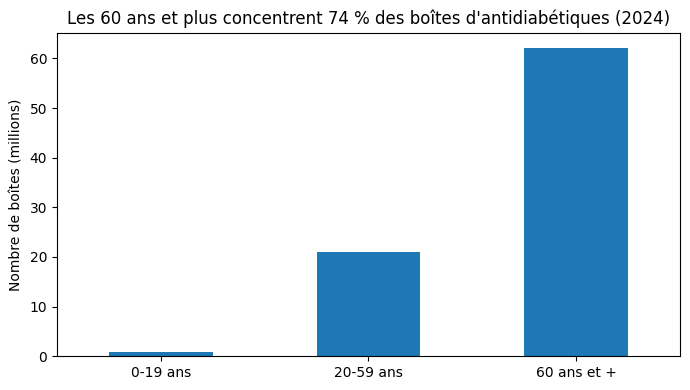

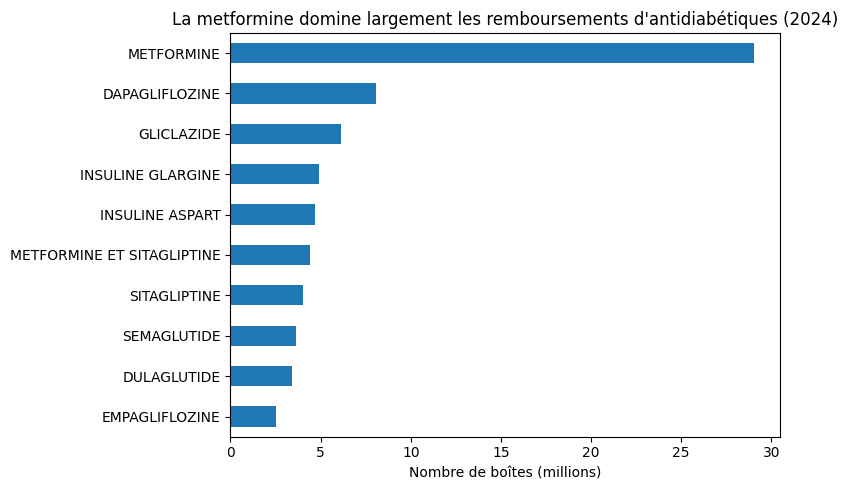

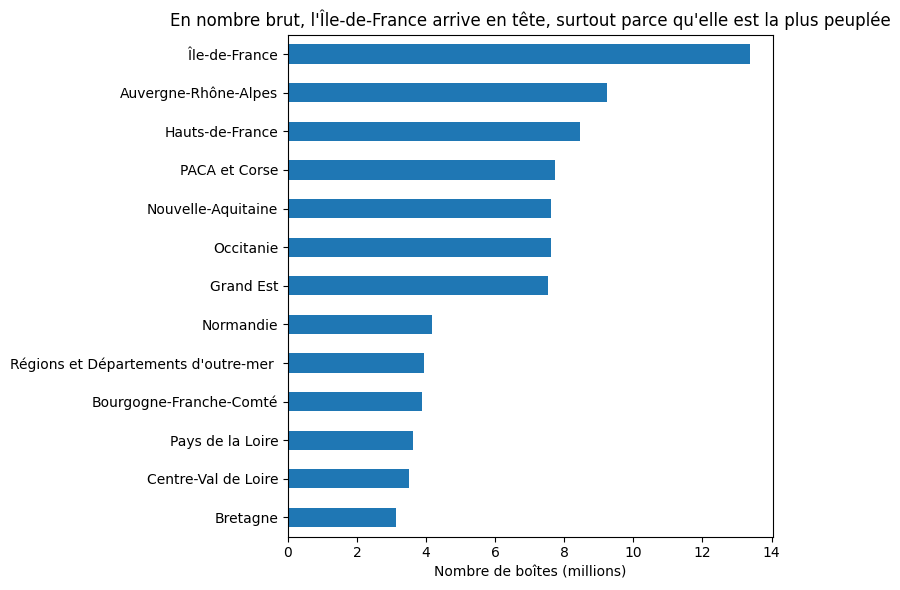

In [16]:
import matplotlib.pyplot as plt

# 1) Traduire les codes en noms lisibles
noms_age = {"0": "0-19 ans", "20": "20-59 ans", "60": "60 ans et +", "99": "Âge inconnu"}
noms_reg = {"11": "Île-de-France", "24": "Centre-Val de Loire", "27": "Bourgogne-Franche-Comté",
            "28": "Normandie", "32": "Hauts-de-France", "44": "Grand Est", "52": "Pays de la Loire",
            "53": "Bretagne", "75": "Nouvelle-Aquitaine", "76": "Occitanie",
            "84": "Auvergne-Rhône-Alpes", "93": "PACA et Corse", "5": "Outre-mer", "99": "Inconnue"}
a10["age_lib"] = a10[COL_AGE].map(noms_age)
a10["region_lib"] = a10[COL_REG].map(noms_reg)

# 2) Graphique 1 : l'âge
age = a10.groupby("age_lib")[COL_BOITES].sum().drop("Âge inconnu") / 1e6
age = age.reindex(["0-19 ans", "20-59 ans", "60 ans et +"])
age.plot(kind="bar", figsize=(7, 4), rot=0)
plt.title("Les 60 ans et plus concentrent 74 % des boîtes d'antidiabétiques (2024)")
plt.ylabel("Nombre de boîtes (millions)")
plt.xlabel("")
plt.tight_layout()
plt.show()

# 3) Graphique 2 : les 10 molécules
top10 = a10.groupby(COL_LIB5)[COL_BOITES].sum().sort_values().tail(10) / 1e6
top10.plot(kind="barh", figsize=(8, 5))
plt.title("La metformine domine largement les remboursements d'antidiabétiques (2024)")
plt.xlabel("Nombre de boîtes (millions)")
plt.ylabel("")
plt.tight_layout()
plt.show()

# 4) Graphique 3 : toutes les régions
reg = a10.groupby("region_lib")[COL_BOITES].sum().drop("Inconnue").sort_values() / 1e6
reg.plot(kind="barh", figsize=(8, 6))
plt.title("En nombre brut, l'Île-de-France arrive en tête, surtout parce qu'elle est la plus peuplée")
plt.xlabel("Nombre de boîtes (millions)")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 6. Conclusions et limites

**5 conclusions chiffrées :**
1. En 2024, l'Assurance maladie a remboursé 84 millions de boîtes d'antidiabétiques en pharmacie de ville, pour un montant de 1 846 millions d'euros.
2. Les 60 ans et plus concentrent 74 % des boîtes d'antidiabétiques en 2024.
3. La metformine est de loin la molécule la plus remboursée : 29,0 millions de boîtes, soit 34,6 % des boîtes d'antidiabétiques.
4. Le classement en euros diffère de celui en boîtes : la metformine représente 34,6 % des boîtes mais seulement 5,4 % des dépenses (3,4 € la boîte), alors que la dapagliflozine est la 1re dépense (303 M€) et que les GLP-1 coûtent 74 à 80 € la boîte.
5. Le diabète est surtout suivi par les médecins généralistes libéraux ; les endocrinologues libéraux ne prescrivent que 5,3 % des boîtes.

**Limites des données :**
1. Open Medic compte des boîtes, pas des patients : on ne sait pas combien de personnes sont soignées.
2. Seule la pharmacie de ville est couverte : les médicaments délivrés à l'hôpital ne sont pas comptés.
3. Il n'y a pas de diagnostic : on ne sait pas pour quelle maladie le médicament a été prescrit (diabète de type 1 ou 2, ou autre usage), et les tranches d'âge sont très larges (20-59 ans, 60 ans et plus).

## Pistes d'amélioration
- Comparer 2020 et 2024 pour mesurer la progression des GLP-1 (classe A10BJ).
- Calculer des boîtes par habitant par région, avec les données de population de l'INSEE.